In [90]:
import pandas as pd
import matplotlib as plt
import seaborn as sns

In [91]:
index_cols = ['unit', 'cycle']                              # engine ID and cycle number
setting_cols = ['setting_1', 'setting_2', 'setting_3']      # operating settings
sensor_cols = [f'sensor_{i}' for i in range(1, 22)]         # sensor_1 ... sensor_21
col_names = index_cols + setting_cols + sensor_cols          # 2 + 3 + 21 = 26

train = pd.read_csv('data/train_FD001.txt', sep=r'\s+', header=None, names=col_names)
test = pd.read_csv('data/test_FD001.txt', sep=r'\s+', header=None, names=col_names)
rul_test = pd.read_csv('data/RUL_FD001.txt', sep=r'\s+', header=None, names=['RUL'])


The data was loaded and the columns were named.The three names of the data sets are train(which is what would be cleaned and used for training the model),test(used for the final evaluation of the model. It goes through the same preprocessing as train, using statistics fitted on train only)and rul_test(which contains the correct number of cycles which the engine has left for confirmation of the models prediction)

In [92]:
print(train.shape)
print(test.shape)
print(rul_test.shape)

(20631, 26)
(13096, 26)
(100, 1)


In [93]:
train.head()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [94]:
max_cycle = train.groupby('unit')['cycle'].max().rename('max_cycle')
train = train.merge(max_cycle, on='unit')
train['RUL'] = train['max_cycle'] - train['cycle']
train = train.drop(columns='max_cycle')

train[['unit', 'cycle', 'RUL']].head()

,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


In [95]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 27 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

In [96]:
train.describe()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
count,20631.000000,20631.000000,20631.000000,20631.000000,20631.0,20631.00,20631.000000,20631.000000,20631.000000,2.063100e+04,...,20631.000000,20631.000000,20631.000000,2.063100e+04,20631.000000,20631.0,20631.0,20631.000000,20631.000000,20631.000000
mean,51.506568,108.807862,-0.000009,0.000002,100.0,518.67,642.680934,1590.523119,1408.933782,1.462000e+01,...,2388.096152,8143.752722,8.442146,3.000000e-02,393.210654,2388.0,100.0,38.816271,23.289705,107.807862
std,29.227633,68.880990,0.002187,0.000293,0.0,0.00,0.500053,6.131150,9.000605,5.329200e-15,...,0.071919,19.076176,0.037505,3.469531e-18,1.548763,0.0,0.0,0.180746,0.108251,68.880990
min,1.000000,1.000000,-0.008700,-0.000600,100.0,518.67,641.210000,1571.040000,1382.250000,1.462000e+01,...,2387.880000,8099.940000,8.324900,3.000000e-02,388.000000,2388.0,100.0,38.140000,22.894200,0.000000
25%,26.000000,52.000000,-0.001500,-0.000200,100.0,518.67,642.325000,1586.260000,1402.360000,1.462000e+01,...,2388.040000,8133.245000,8.414900,3.000000e-02,392.000000,2388.0,100.0,38.700000,23.221800,51.000000
50%,52.000000,104.000000,0.000000,0.000000,100.0,518.67,642.640000,1590.100000,1408.040000,1.462000e+01,...,2388.090000,8140.540000,8.438900,3.000000e-02,393.000000,2388.0,100.0,38.830000,23.297900,103.000000
75%,77.000000,156.000000,0.001500,0.000300,100.0,518.67,643.000000,1594.380000,1414.555000,1.462000e+01,...,2388.140000,8148.310000,8.465600,3.000000e-02,394.000000,2388.0,100.0,38.950000,23.366800,155.000000
max,100.000000,362.000000,0.008700,0.000600,100.0,518.67,644.530000,1616.910000,1441.490000,1.462000e+01,...,2388.560000,8293.720000,8.584800,3.000000e-02,400.000000,2388.0,100.0,39.430000,23.618400,361.000000


In [97]:
missing = train.isnull().sum().sort_values(ascending = False)
print(missing)

unit         0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
RUL          0
dtype: int64


In [98]:
train.duplicated().sum()

np.int64(0)

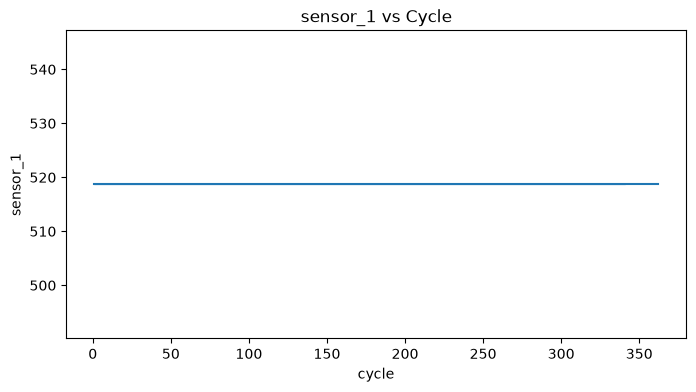

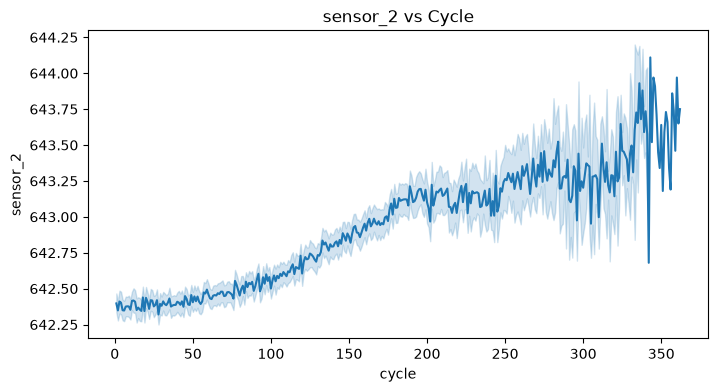

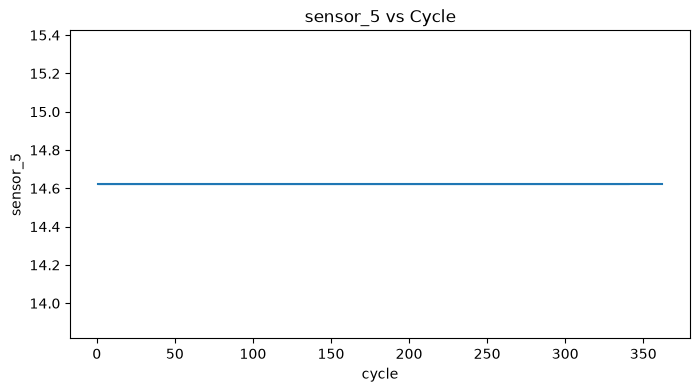

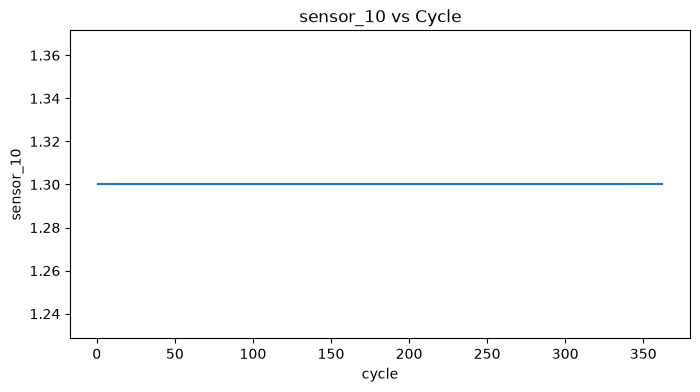

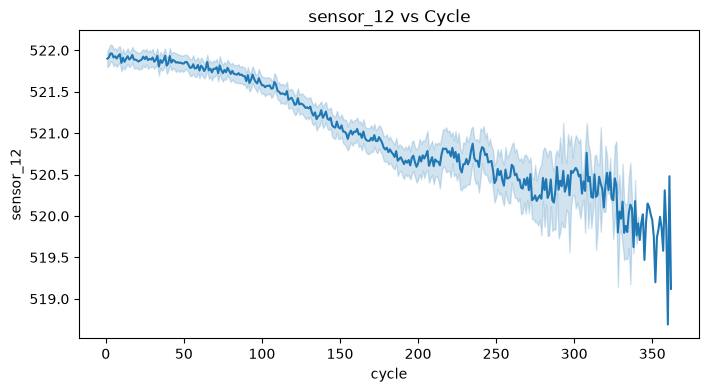

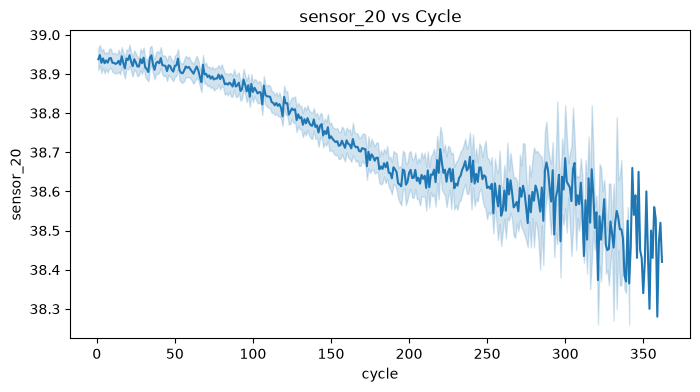

In [99]:
import matplotlib.pyplot as plt
import seaborn as sns

subset = ['sensor_1', 'sensor_2','sensor_5','sensor_10','sensor_12','sensor_20']

for cols in subset:
    plt.figure(figsize=(8, 4))
    sns.lineplot(x='cycle', y=cols, data=train)
    plt.title(f'{cols} vs Cycle')
    plt.show()
    #Positive correlation with cycle: the sensor reading rises as the engine ages (like sensor_2).
#Negative correlation with cycle: the sensor reading falls as the engine ages.

In [100]:
stats = pd.DataFrame({
    'corr_with_RUL': train[sensor_cols].corrwith(train['RUL'])
}).round(3)
print(stats.sort_values('corr_with_RUL'))

           corr_with_RUL
sensor_11         -0.696
sensor_4          -0.679
sensor_15         -0.643
sensor_2          -0.606
sensor_17         -0.606
sensor_3          -0.585
sensor_8          -0.564
sensor_13         -0.563
sensor_9          -0.390
sensor_14         -0.307
sensor_6          -0.128
sensor_5           0.000
sensor_16         -0.000
sensor_20          0.629
sensor_21          0.636
sensor_7           0.657
sensor_12          0.672
sensor_1             NaN
sensor_10            NaN
sensor_18            NaN
sensor_19            NaN


c:\Users\alegb\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\alegb\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [101]:
corr = train[sensor_cols].corrwith(train['RUL'])

drop_sensors = []
keep_sensors = []

for sensor in sensor_cols:
    c = corr[sensor]
    if pd.isna(c) or abs(c) < 0.15:
        drop_sensors.append(sensor)
    else:
        keep_sensors.append(sensor)

print('Drop:', drop_sensors)     # expect sensors 1, 5, 6, 10, 16, 18, 19
print('Keep:', keep_sensors)   # expect 14

Drop: ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Keep: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


c:\Users\alegb\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\alegb\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [102]:
stats = pd.DataFrame({
    'corr_with_RUL': train[setting_cols].corrwith(train['RUL'])
}).round(3)
print(stats.sort_values('corr_with_RUL'))

           corr_with_RUL
setting_1         -0.003
setting_2         -0.002
setting_3            NaN


In [103]:
drop_settings = setting_cols

In [104]:
drop =  drop_sensors + drop_settings
def select_features(df):
    return df.drop(columns = drop)

In [105]:
train = select_features(train)
test = select_features(test)
print(test.shape,train.shape)

(13096, 16) (20631, 17)


In [106]:
test

,unit,cycle,sensor_2,sensor_3,sensor_4,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,643.02,1585.29,1398.21,553.90,2388.04,9050.17,47.20,521.72,2388.03,8125.55,8.4052,392,38.86,23.3735
1,1,2,641.71,1588.45,1395.42,554.85,2388.01,9054.42,47.50,522.16,2388.06,8139.62,8.3803,393,39.02,23.3916
2,1,3,642.46,1586.94,1401.34,554.11,2388.05,9056.96,47.50,521.97,2388.03,8130.10,8.4441,393,39.08,23.4166
3,1,4,642.44,1584.12,1406.42,554.07,2388.03,9045.29,47.28,521.38,2388.05,8132.90,8.3917,391,39.00,23.3737
4,1,5,642.51,1587.19,1401.92,554.16,2388.01,9044.55,47.31,522.15,2388.03,8129.54,8.4031,390,38.99,23.4130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13091,100,194,643.24,1599.45,1415.79,553.41,2388.02,9142.37,47.69,520.69,2388.00,8213.28,8.4715,394,38.65,23.1974
13092,100,195,643.22,1595.69,1422.05,553.22,2388.05,9140.68,47.60,521.05,2388.09,8210.85,8.4512,395,38.57,23.2771
13093,100,196,643.44,1593.15,1406.82,553.04,2388.11,9146.81,47.57,521.18,2388.04,8217.24,8.4569,395,38.62,23.2051
13094,100,197,643.26,1594.99,1419.36,553.37,2388.07,9148.85,47.61,521.33,2388.08,8220.48,8.4711,395,38.66,23.2699


## Capping
An engine that is healthy looks the same whether it has 300 cycles left or 200. The wear that the sensors pick up only becomes visible in the last stretch of its life. So for the early cycles, the sensor readings contain almost no information about exactly how many cycles remain, yet the uncapped target asks the model to tell 300 from 200 anyway.

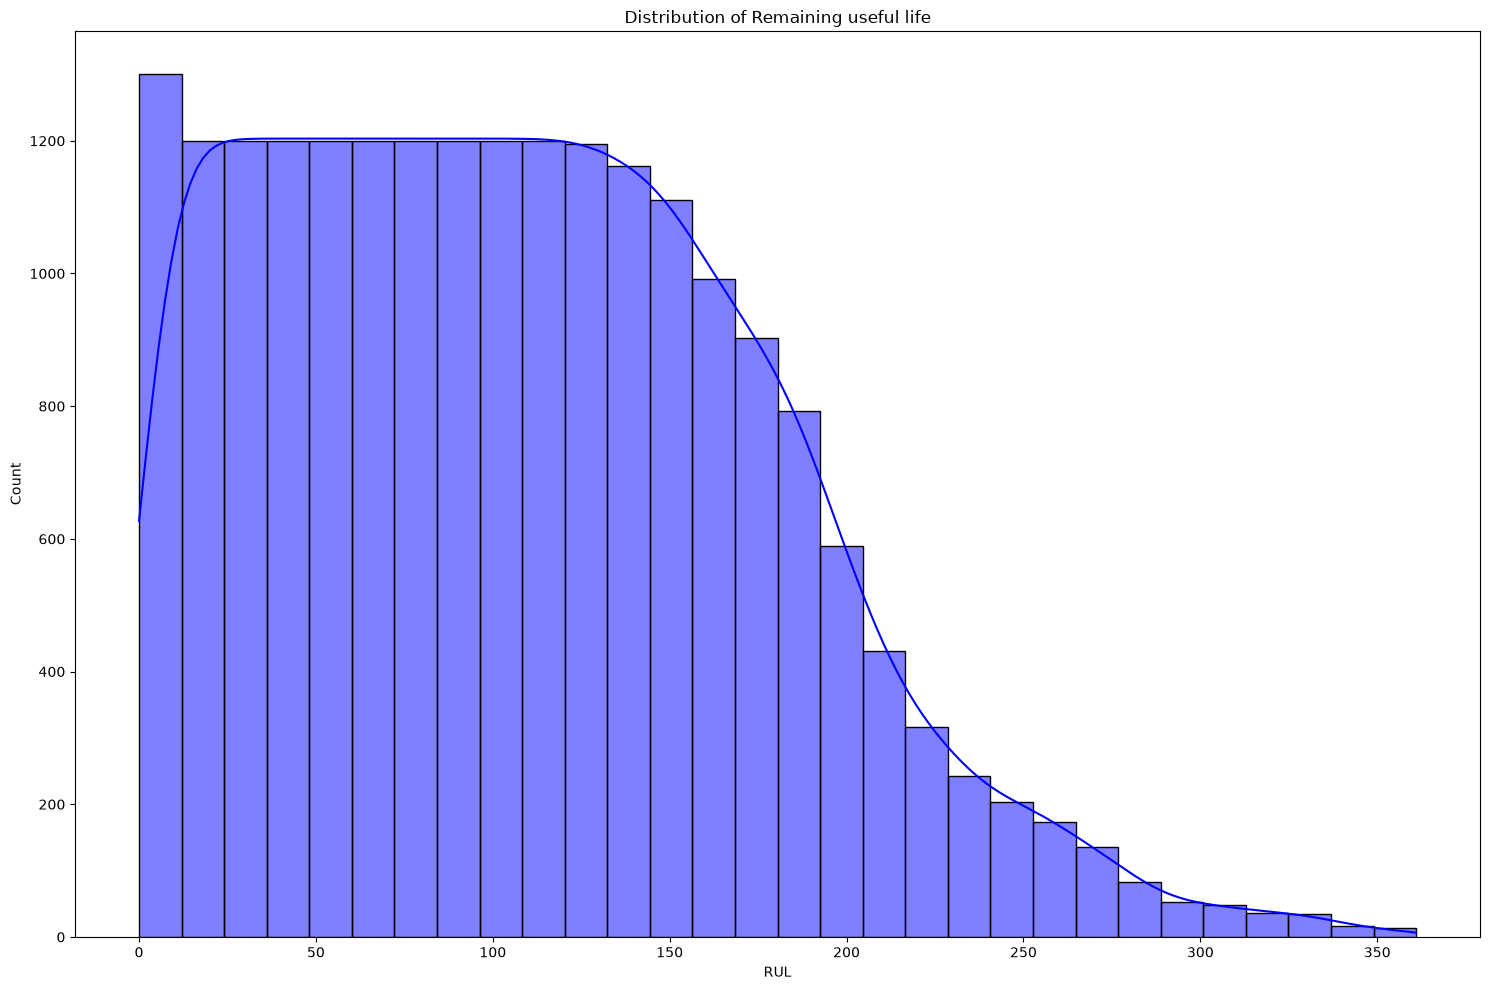

In [107]:
plt.figure(figsize = (15,10))
sns.histplot(train['RUL'], bins = 30 , color= 'blue', edgecolor = 'black',kde = True)
plt.title('Distribution of Remaining useful life')
plt.tight_layout()

The bulk of the data sits at the lower rul numbers thats why it is right skewed 

In [108]:
train['Rul_capped'] = train['RUL'].clip(lower = 0, upper = 125)

Text(0.5, 1.0, 'distribution of Remaining useful life after capping')

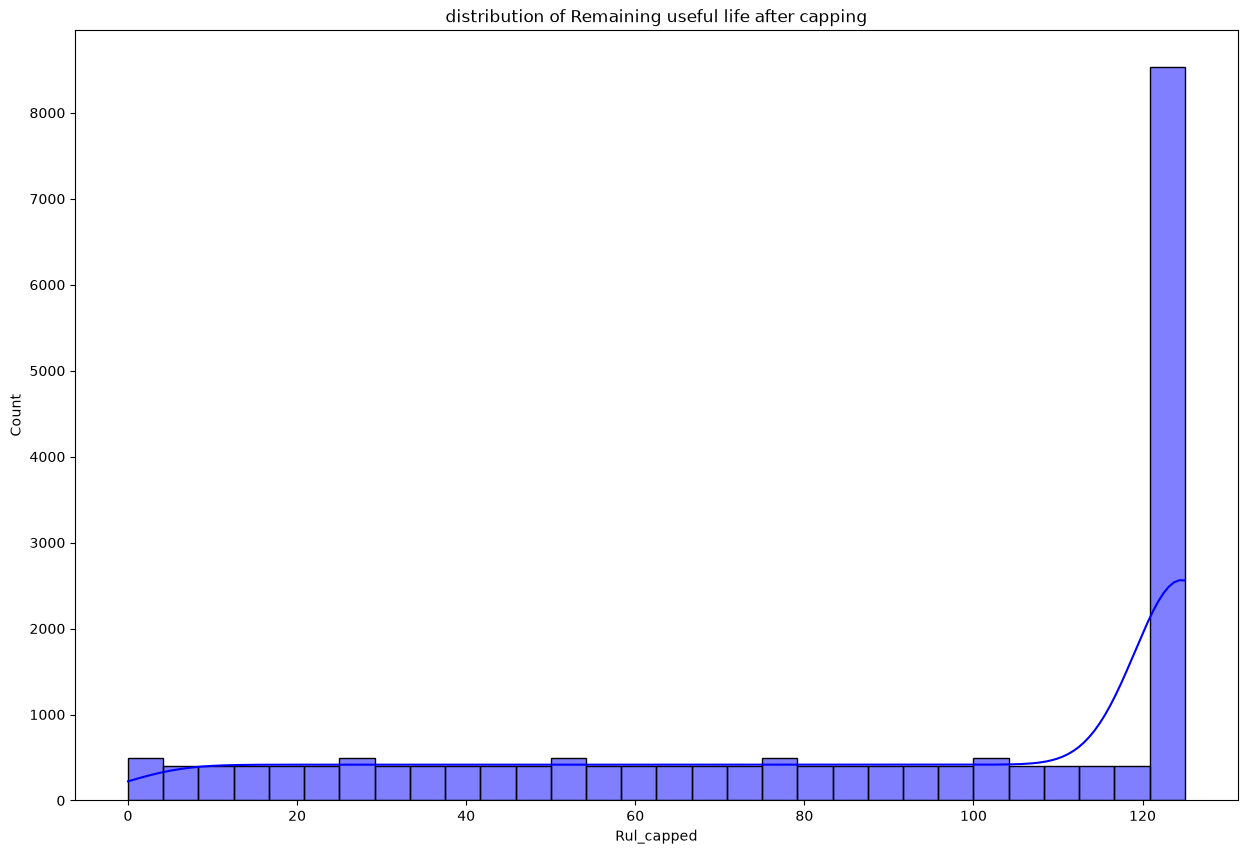

In [109]:
plt.figure(figsize = (15,10))
sns.histplot(train['Rul_capped'], bins = 30, color = 'blue', edgecolor = 'black', kde = True)
plt.title('distribution of Remaining useful life after capping')

since the the high rul numbers were capped at 125 thats why it is left sked and here is a long bar at 125

In [110]:
for sensor in keep_sensors:
    train[sensor + '_mean10'] = train.groupby('unit')[sensor].transform(lambda x: x.rolling(10, min_periods=1).mean())
    test[sensor + '_mean10'] = test.groupby('unit')[sensor].transform(lambda x: x.rolling(10, min_periods=1).mean())

print(train.shape, test.shape)

(20631, 32) (13096, 30)


In [111]:
train.sensor_2_mean10

0        641.820000
1        641.985000
2        642.106667
3        642.167500
4        642.208000
            ...    
20626    643.456000
20627    643.447000
20628    643.470000
20629    643.424000
20630    643.497000
Name: sensor_2_mean10, Length: 20631, dtype: float64

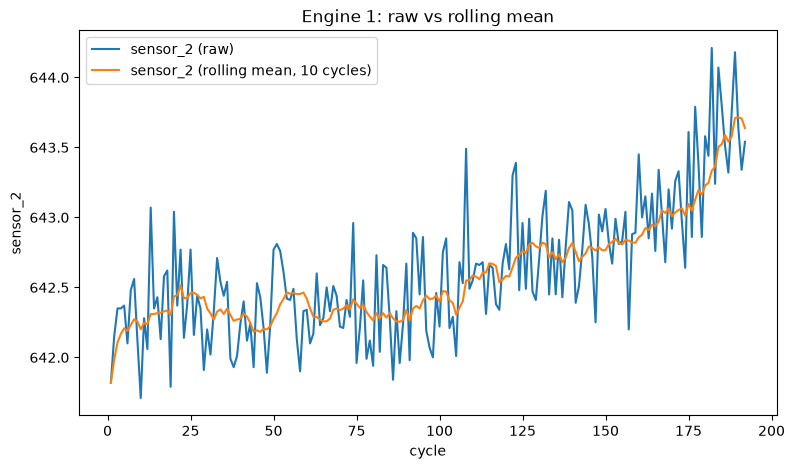

In [115]:
e1 = train[train['unit'] == 1]

plt.figure(figsize=(9, 5))
plt.plot(e1['cycle'], e1['sensor_2'], label='sensor_2 (raw)')
plt.plot(e1['cycle'], e1['sensor_2_mean10'], label='sensor_2 (rolling mean, 10 cycles)')
plt.xlabel('cycle')
plt.ylabel('sensor_2')
plt.title('Engine 1: raw vs rolling mean')
plt.legend()
plt.show()